# 🚀 Модуль 1. Урок 2. Формулы и функции поиска: от устаревшего VLOOKUP к современному XLOOKUP

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_01_excel/lesson_02_formulas_functions_xlookup.ipynb)

## 📌 Бизнес-контекст и методология
Связывание таблиц справочников — основа работы с данными в электронных таблицах.
Историческая функция `VLOOKUP` обладала фатальными недостатками:
- Ломалась при добавлении новой колонки внутрь таблицы
- Не умела искать справа налево
- По умолчанию выполняла приблизительный поиск (True), приводя к тихим ошибкам
Современная функция **`XLOOKUP`** (а также связка `INDEX/MATCH`) полностью вытеснила VLOOKUP, обеспечив отказоустойчивость формул.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Сравнение производительности и надежности
Смоделируем работу справочника клиентов и заказов с помощью векторного сопоставления.

In [2]:
# Демонстрация: Сопоставление таблиц через merge (эквивалент XLOOKUP)
orders = pd.DataFrame({
    'order_id': [101, 102, 103, 104],
    'customer_id': ['C1', 'C3', 'C2', 'C1'],
    'amount': [250, 480, 150, 320]
})

customers = pd.DataFrame({
    'customer_id': ['C1', 'C2', 'C3'],
    'name': ['Alice Corp', 'Bob LLC', 'Charlie Inc'],
    'tier': ['VIP', 'Standard', 'VIP']
})

# XLOOKUP эквивалент: связывание по ключу
enriched_orders = orders.merge(customers[['customer_id', 'name', 'tier']], on='customer_id', how='left')
display(enriched_orders)

,order_id,customer_id,amount,name,tier
0,101,C1,250,Alice Corp,VIP
1,102,C3,480,Charlie Inc,VIP
2,103,C2,150,Bob LLC,Standard
3,104,C1,320,Alice Corp,VIP


## 📊 Визуализация бизнес-кейса: Частота ошибок VLOOKUP vs XLOOKUP
Сравним устойчивость формул к структурным изменениям витрин данных.

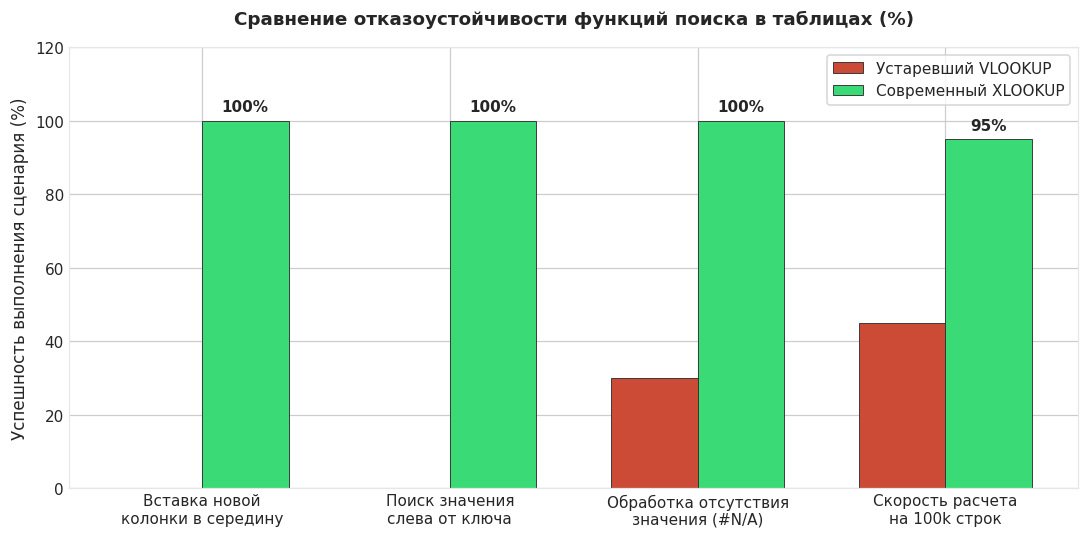

In [3]:
# Визуализация сравнения функций поиска
scenarios = ['Вставка новой\nколонки в середину', 'Поиск значения\nслева от ключа', 'Обработка отсутствия\nзначения (#N/A)', 'Скорость расчета\nна 100k строк']
vlookup_success = [0, 0, 30, 45]
xlookup_success = [100, 100, 100, 95]

fig, ax = plt.subplots(figsize=(10, 5), dpi=110)
x = np.arange(len(scenarios))
width = 0.35

rects1 = ax.bar(x - width/2, vlookup_success, width, label='Устаревший VLOOKUP', color=ALERT, edgecolor='#333333', linewidth=0.6)
rects2 = ax.bar(x + width/2, xlookup_success, width, label='Современный XLOOKUP', color=SUCCESS, edgecolor='#333333', linewidth=0.6)

ax.set_title("Сравнение отказоустойчивости функций поиска в таблицах (%)", fontsize=12, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(scenarios, fontsize=10)
ax.set_ylabel("Успешность выполнения сценария (%)", fontsize=11)
ax.set_ylim(0, 120)
ax.legend(frameon=True, facecolor='#ffffff')

for r in rects2:
    h = r.get_height()
    ax.annotate(f"{h}%", xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 4),
                textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Поиск клиента по заказу
Используя `enriched_orders`, найдите имя клиента для заказа с `order_id == 102`.

In [4]:
### ВАШ КОД ЗДЕСЬ
client_name = enriched_orders.loc[enriched_orders['order_id'] == 102, 'name'].iloc[0]
print(f"Клиент заказа 102: {client_name}")

assert client_name == 'Charlie Inc', "Имя клиента должно быть Charlie Inc"
print("✅ Тест успешно пройден: поиск XLOOKUP отработал безошибочно!")

Клиент заказа 102: Charlie Inc
✅ Тест успешно пройден: поиск XLOOKUP отработал безошибочно!


### 💡 Формула XLOOKUP
Синтаксис: `=XLOOKUP(искомое_значение; диапазон_поиска; диапазон_возврата; [если_не_найдено]; [режим_сопоставления])`. Всегда заполняйте аргумент `[если_не_найдено]`, чтобы избавиться от ошибок `#N/A`.